In [2]:
import sympy as sp



# Wave-speed variables

rho, c11, c22, c33, c23, c13, c12, cs3, cs1, cs2 = sp.symbols(

    "rho c11 c22 c33 c23 c13 c12 cs3 cs1 cs2"

)
L1, L2, L3, Ls3, Ls1, Ls2, t11, t22, t33, t12, t23, t13, ts3, ts1, ts2, td = sp.symbols(
    "L_1 L_2 L_3 L_{s3} L_{s1} L_{s2} "
    "t_{11} t_{22} t_{33} t_{12} t_{23} t_{13} "
    "t_{s3} t_{s1} t_{s2} t_d"
)


# Independent stiffness coefficients: invert this compact symbolic matrix first

C11, C22, C33, C44, C55, C66, C12, C23, C13 = sp.symbols(

    "C11 C22 C33 C44 C55 C66 C12 C23 C13"

)

C_symbolic = sp.Matrix([

    [C11, C12, C13, 0, 0, 0],

    [C12, C22, C23, 0, 0, 0],

    [C13, C23, C33, 0, 0, 0],

    [0, 0, 0, C44, 0, 0],

    [0, 0, 0, 0, C55, 0],

    [0, 0, 0, 0, 0, C66],

])



S_symbolic = C_symbolic.inv()



# Substitute the physical definitions only after inversion

C_substitutions = {

    C11: rho*c11**2,

    C22: rho*c22**2,

    C33: rho*c33**2,

    C44: rho*c23**2,

    C55: rho*c13**2,

    C66: rho*c12**2,

}

C_substitutions.update({
     C12: sp.sqrt(
            (C_substitutions[C11] + C_substitutions[C66] - 2*rho*cs3**2) *
            (C_substitutions[C22] + C_substitutions[C66] - 2*rho*cs3**2)
        ) - C_substitutions[C66], # type: ignore
    
        C13: sp.sqrt(
            (C_substitutions[C11] + C_substitutions[C55] - 2*rho*cs1**2) *
            (C_substitutions[C33] + C_substitutions[C55] - 2*rho*cs1**2)
        ) - C_substitutions[C55], # type: ignore
    
        C23: sp.sqrt(
            (C_substitutions[C22] + C_substitutions[C44] - 2*rho*cs2**2) *
            (C_substitutions[C33] + C_substitutions[C44] - 2*rho*cs2**2)
        ) - C_substitutions[C44] # type: ignore
})
# nominal = {
#     c11: 2.18,
#     c12: 1.29,
#     c13: 1.28,
#     c22: 2.22,
#     c23: 1.26,
#     c33: 2.24,
#     cs3: 2.19,
#     cs1: 2.22,
#     cs2: 2.21,
#     rho: 1.19
# }

nominal={
    L1:24.66,
    L2:24.77,
    L3:24.78,
    Ls3:24.92,
    Ls1:25,
    Ls2:25.02,
    rho:1.19,
    td:0
}

nominal.update({
    t11:nominal[L1]/2.18,
    t22:nominal[L2]/2.22,
    t33:nominal[L3]/2.24,
    t12:nominal[L1]/1.29,
    t13:nominal[L1]/1.28,
    t23:nominal[L3]/1.26,
    ts3:nominal[Ls3]/2.19,
    ts1:nominal[Ls1]/2.22,
    ts2:nominal[Ls2]/2.21
})

velocities={
    c11: L1/(t11-td),
    c12: L1/(t12-td),
    c13: L1/(t13-td),
    c22: L2/(t22-td),
    c23: L2/(t23-td),
    c33: L3/(t33-td),
    cs3: Ls3/(ts3-td),
    cs1: Ls1/(ts1-td),
    cs2: Ls2/(ts2-td),
}

S_mat=S_symbolic.subs(C_substitutions).subs(velocities)
print(S_mat[0,0].free_symbols)
E_indices=[0,1,2]

# variables=[
#     L1, L2, L3, Ls3, Ls1, Ls2, t11, t22, t33, t12, t23, t13, ts3, ts1, ts2, td
# ]
sensitivities={}

for index in E_indices:
    variables=S_mat[index,index].free_symbols
    E=1/S_mat[index,index]
    print(f"Nominal E{index+1}: {E.subs(nominal)}")

    if f"E{index+1}" not in sensitivities.keys():
        sensitivities[f"E{index+1}"]={}
    for x in variables:
        
        
        # Analytical derivative
        dE_dx = sp.diff(E, x)

        # Evaluate derivative at nominal values
        sensitivity = float(dE_dx.subs(nominal))

        print(
            f"dE{index+1}/d{x} = {sensitivity:.6g}"
        )
        sensitivities[f"E{index+1}"][x]=sensitivity



{t_{s2}, L_{s2}, t_{12}, L_2, t_{33}, t_{s1}, t_{s3}, t_{23}, t_{13}, L_3, L_1, t_{11}, rho, L_{s1}, t_d, t_{22}, L_{s3}}
Nominal E1: 4.76912385021871
dE1/dt_{s2} = -0.222867
dE1/dL_{s2} = 0.100845
dE1/dt_{12} = -0.164726
dE1/dL_2 = 0.0571072
dE1/dt_{33} = -0.327785
dE1/dt_{s1} = 1.13845
dE1/dt_{s3} = 0.797736
dE1/dt_{23} = 0.0416673
dE1/dt_{13} = -0.221137
dE1/dL_3 = 0.146333
dE1/dL_1 = 0.968058
dE1/dt_{11} = -1.45537
dE1/drho = 4.00767
dE1/dL_{s1} = -0.512817
dE1/dt_d = 0.614247
dE1/dt_{22} = -0.200221
dE1/dL_{s3} = -0.364263
Nominal E2: 5.02267402725850
dE2/dt_{s2} = 1.03803
dE2/dL_{s2} = -0.469696
dE2/dt_{12} = -0.173484
dE2/dL_2 = 0.847623
dE2/dt_{33} = -0.286157
dE2/dt_{s1} = -0.220545
dE2/dt_{s3} = 0.840148
dE2/dt_{23} = -0.19407
dE2/dt_{13} = 0.0428395
dE2/dL_3 = 0.127749
dE2/dL_1 = 0.191092
dE2/dt_{11} = -0.196366
dE2/drho = 4.22073
dE2/dL_{s1} = 0.0993448
dE2/dt_d = 0.68926
dE2/dt_{22} = -1.53965
dE2/dL_{s3} = -0.383629
Nominal E3: 4.92477122141942
dE3/dt_{s2} = 1.01779
dE3/d

FFT peak: 0.795775 Hz (5.000000 rad/s)


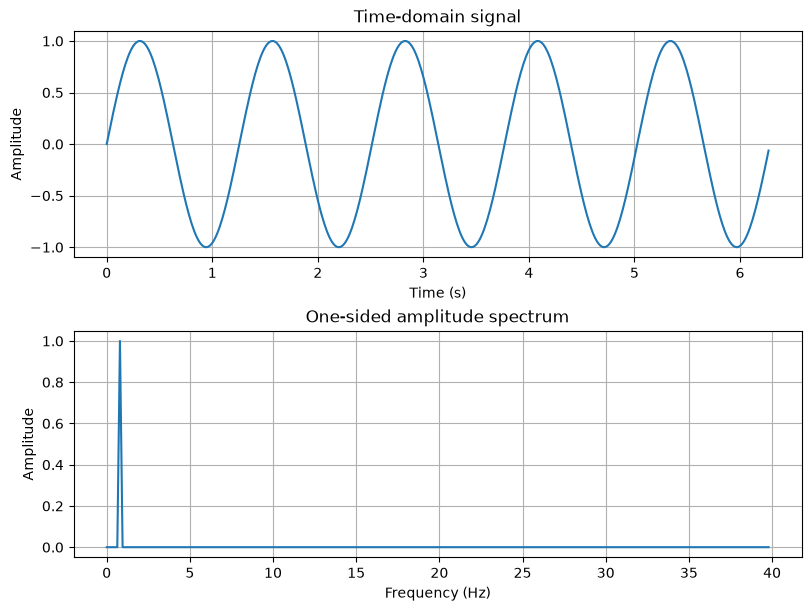

In [18]:
import numpy as np

import matplotlib.pyplot as plt



angular_frequency = 5  # rad/s

period = 2 * np.pi / angular_frequency

sample_count = 500



# Exclude the endpoint so every FFT sample is equally spaced without duplicating a period boundary.

points = np.linspace(0, 5 * period, sample_count, endpoint=False)

sample_spacing = points[1] - points[0]

data = np.sin(angular_frequency * points)



# Real-valued input has a symmetric FFT, so retain only the non-negative frequencies.

spectrum = np.fft.rfft(data)

frequencies = np.fft.rfftfreq(sample_count, d=sample_spacing)

amplitude = np.abs(spectrum) / sample_count

amplitude[1:-1] *= 2



fig, axes = plt.subplots(2, 1, figsize=(8, 6), constrained_layout=True)



axes[0].plot(points, data)

axes[0].set(xlabel="Time (s)", ylabel="Amplitude", title="Time-domain signal")

axes[0].grid(True)



axes[1].plot(frequencies, amplitude)

axes[1].set(

    xlabel="Frequency (Hz)",

    ylabel="Amplitude",

    title="One-sided amplitude spectrum",

)

axes[1].grid(True)



peak_frequency = frequencies[np.argmax(amplitude)]

print(f"FFT peak: {peak_frequency:.6f} Hz ({2 * np.pi * peak_frequency:.6f} rad/s)")

plt.show()


2.5e-12
[0.0000000e+00 2.5000000e-12 5.0000000e-12 ... 4.9999925e-06 4.9999950e-06
 4.9999975e-06]


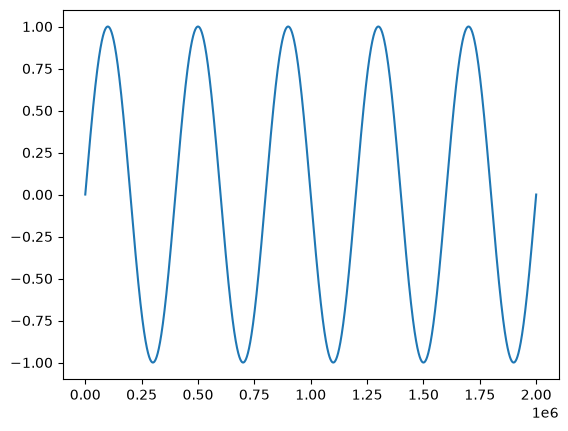

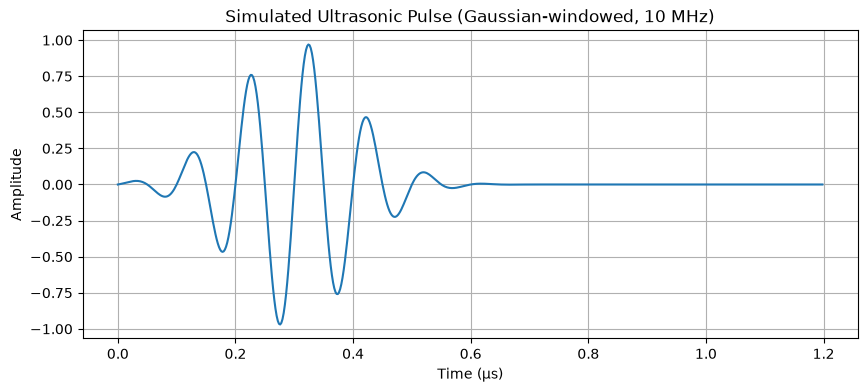

In [ ]:
import numpy as np

import matplotlib.pyplot as plt

number_of_cycles=5
frequency_hz=1*10**6

angular_frequency=2*np.pi*frequency_hz
period=1/frequency_hz
nSamples=(period*number_of_cycles)/(frequency_hz*2)

print(nSamples)
times=np.arange(0,number_of_cycles*period,nSamples)
data=np.sin(times*angular_frequency)

print(times)
plt.plot(data)



In [ ]:
def generate_pulse(
    center_frequency: float,
    number_of_cycles: int,
    lead_time: float = 0.0,
    attenuation_db: float = 0.0,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float]:

    fs = center_frequency * 15
    dt = 1 / fs
    pulse_length = number_of_cycles / center_frequency

    t0 = pulse_length
    sigma = pulse_length / 3
    receiving_center = t0 + lead_time
    padding = 4 * sigma

    t = np.arange(
        min(t0, receiving_center) - padding,
        max(t0, receiving_center) + padding + dt,
        dt,
    )

    def waveform(time):
        envelope = np.exp(-((time - t0) ** 2) / (2 * sigma**2))
        return envelope * np.sin(2 * np.pi * center_frequency * time)

    transmitted_pulse = waveform(t)

    attenuation_factor = 10 ** (-attenuation_db / 20)
    receiving_pulse = attenuation_factor * waveform(t - lead_time)

    frequency_resolution = fs / len(t)

    return t, transmitted_pulse, receiving_pulse, frequency_resolution


lead_time = 10e-6
attenuation_db = 4

t, pulse, receiving_pulse, frequency_resolution = generate_pulse(
    2e6, 10, lead_time, attenuation_db
)

plt.figure(figsize=(10, 4))
plt.plot(t * 1e6, abs(pulse), label="Transmitting probe")
plt.plot(t * 1e6, abs(receiving_pulse), label=f"Receiving probe ({attenuation_db} dB loss)")
tx_peak_index = np.argmax(pulse)
rx_peak_index = np.argmax(receiving_pulse)

tx_peak_time = t[tx_peak_index] * 1e6
rx_peak_time = t[rx_peak_index] * 1e6
delta_t = rx_peak_time - tx_peak_time

plt.scatter(
    [tx_peak_time, rx_peak_time],
    [pulse[tx_peak_index], receiving_pulse[rx_peak_index]],
    color="black",
    zorder=3,
)

arrow_y = 1.1 * max(pulse.max(), receiving_pulse.max())
plt.annotate(
    "",
    xy=(rx_peak_time, arrow_y),
    xytext=(tx_peak_time, arrow_y),
    arrowprops={"arrowstyle": "<->", "color": "black"},
)
plt.text(
    (tx_peak_time + rx_peak_time) / 2,
    arrow_y,
    f"Δt = {delta_t:.2f} µs",
    ha="center",
    va="bottom",
)

plt.xlabel("Time (µs)")
plt.ylabel("Amplitude")
plt.ylim(top=max(pulse)*1.5,bottom=-max(pulse)*1.5)
plt.title("Simulated ultrasonic pulses")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


NameError: name 'np' is not defined

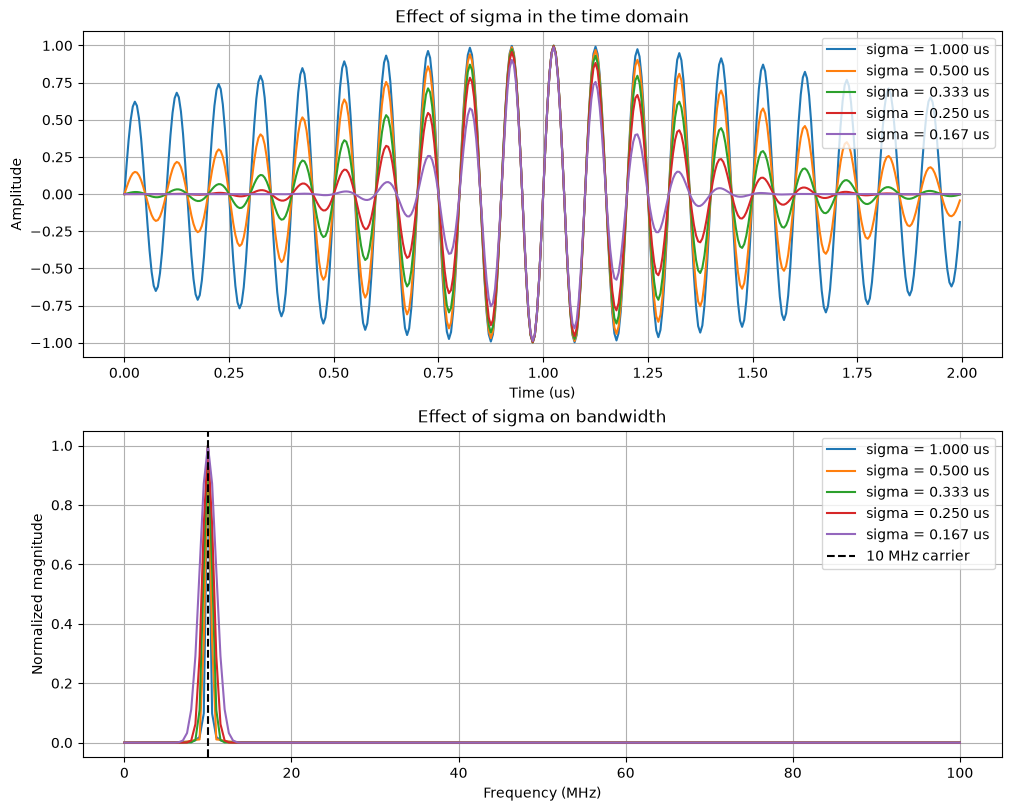

In [24]:
import numpy as np

import matplotlib.pyplot as plt





def generate_pulse(

    center_frequency: float,

    number_of_cycles: int,

    sigma_divisor: float,

    samples_per_cycle: int = 20,

) -> tuple[np.ndarray, np.ndarray, float]:

    fs = center_frequency * samples_per_cycle

    dt = 1 / fs

    pulse_length = number_of_cycles / center_frequency

    t0 = pulse_length



    t = np.arange(0, 2 * pulse_length, dt)

    sigma = pulse_length / sigma_divisor

    envelope = np.exp(-((t - t0) ** 2) / (2 * sigma**2))

    pulse = envelope * np.sin(2 * np.pi * center_frequency * (t - t0))



    return t, pulse, fs





fo = 10e6

number_of_cycles = 10

sigma_divisors = [1, 2, 3, 4, 6]



fig, axes = plt.subplots(2, 1, figsize=(10, 8), constrained_layout=True)



for divisor in sigma_divisors:

    t, pulse, fs = generate_pulse(fo, number_of_cycles, divisor)

    sigma = (number_of_cycles / fo) / divisor

    sigma_label = f"sigma = {sigma * 1e6:.3f} us"



    axes[0].plot(t * 1e6, pulse, label=sigma_label)



    fft_data = np.fft.rfft(pulse)

    frequencies = np.fft.rfftfreq(len(pulse), d=1 / fs)

    amplitude = np.abs(fft_data)

    amplitude /= amplitude.max()

    axes[1].plot(frequencies / 1e6, amplitude, label=sigma_label)



axes[0].set(

    xlabel="Time (us)",

    ylabel="Amplitude",

    title="Effect of sigma in the time domain",

)

axes[0].grid(True)

axes[0].legend()



axes[1].axvline(fo / 1e6, color="black", linestyle="--", label="10 MHz carrier")

axes[1].set(

    xlabel="Frequency (MHz)",

    ylabel="Normalized magnitude",

    title="Effect of sigma on bandwidth",

)

axes[1].grid(True)

axes[1].legend()



plt.show()


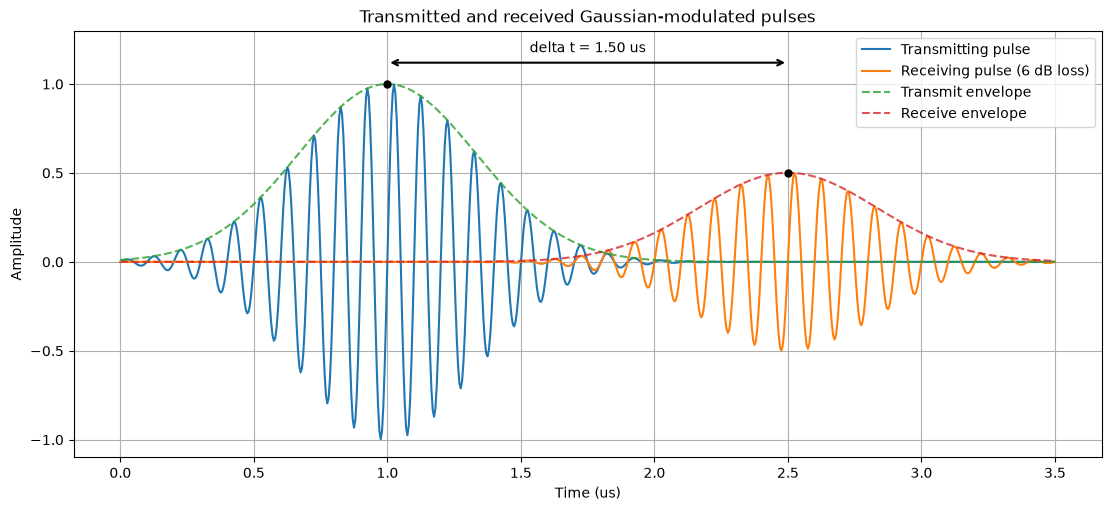

In [25]:
import numpy as np

import matplotlib.pyplot as plt



center_frequency = 10e6

number_of_cycles = 10

sigma_divisor = 3

samples_per_cycle = 20

delta_t = 1.5e-6

attenuation_db = 6



fs = center_frequency * samples_per_cycle

dt = 1 / fs

pulse_length = number_of_cycles / center_frequency

sigma = pulse_length / sigma_divisor

tx_peak_time = pulse_length

rx_peak_time = tx_peak_time + delta_t

attenuation = 10 ** (-attenuation_db / 20)



t = np.arange(0, rx_peak_time + pulse_length + dt, dt)



tx_envelope = np.exp(-((t - tx_peak_time) ** 2) / (2 * sigma**2))

rx_envelope = attenuation * np.exp(-((t - rx_peak_time) ** 2) / (2 * sigma**2))



tx_pulse = tx_envelope * np.sin(

    2 * np.pi * center_frequency * (t - tx_peak_time)

)

rx_pulse = rx_envelope * np.sin(

    2 * np.pi * center_frequency * (t - rx_peak_time)

)



fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)

ax.plot(t * 1e6, tx_pulse, label="Transmitting pulse")

ax.plot(t * 1e6, rx_pulse, label=f"Receiving pulse ({attenuation_db} dB loss)")

ax.plot(t * 1e6, tx_envelope, "--", alpha=0.8, label="Transmit envelope")

ax.plot(t * 1e6, rx_envelope, "--", alpha=0.8, label="Receive envelope")



arrow_y = 1.12

tx_peak_us = tx_peak_time * 1e6

rx_peak_us = rx_peak_time * 1e6

ax.annotate(

    "",

    xy=(rx_peak_us, arrow_y),

    xytext=(tx_peak_us, arrow_y),

    arrowprops={"arrowstyle": "<->", "color": "black", "linewidth": 1.5},

)

ax.text(

    (tx_peak_us + rx_peak_us) / 2,

    arrow_y + 0.04,

    f"delta t = {delta_t * 1e6:.2f} us",

    ha="center",

    va="bottom",

)

ax.scatter(

    [tx_peak_us, rx_peak_us],

    [1, attenuation],

    color="black",

    s=25,

    zorder=3,

)



ax.set(

    xlabel="Time (us)",

    ylabel="Amplitude",

    title="Transmitted and received Gaussian-modulated pulses",

    ylim=(-1.1, 1.3),

)

ax.grid(True)

ax.legend()

plt.show()


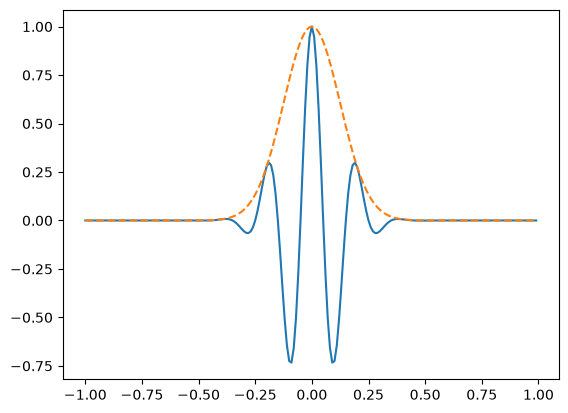

In [9]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
t = np.linspace(-1, 1, 2 * 100, endpoint=False)
i, q, e = signal.gausspulse(t, fc=5,bw=0.6, retquad=True, retenv=True)
plt.plot(t, i, t, e, '--')

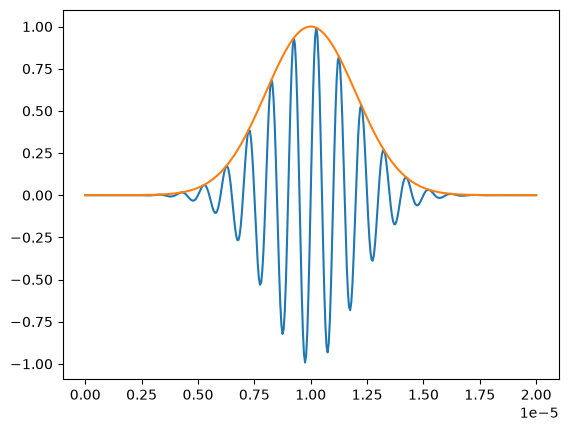

In [61]:
import numpy as np
from numpy import ndarray
import matplotlib.pyplot as plt
import time
from scipy import signal

def generate_pulse(center_frequency: float,
                   number_of_cycles: int) -> tuple[np.ndarray, np.ndarray, float]:

    fc = center_frequency
    cycles = number_of_cycles

    fs = fc * 20
    dt = 1 / fs

    pulse_length = cycles / fc

    # Centre the Gaussian in the waveform
    t = np.arange(0, 2 * pulse_length, dt)
    t0 = pulse_length

    # Gaussian envelope
    sigma = pulse_length / 5
    envelope = np.exp(-((t - t0) ** 2) / (2 * sigma ** 2))

    # Carrier
    pulse = envelope * np.sin(2 * np.pi * fc * t)

    waveform_frequency = fs / len(t)

    return t, pulse, waveform_frequency

    
t,pulse,_=generate_pulse(1e6,10)
hilber=signal.hilbert(pulse)
plt.plot(t,pulse)
plt.plot(t,np.abs(hilber))

Text(0, 0.5, 'Amplitude (V)')

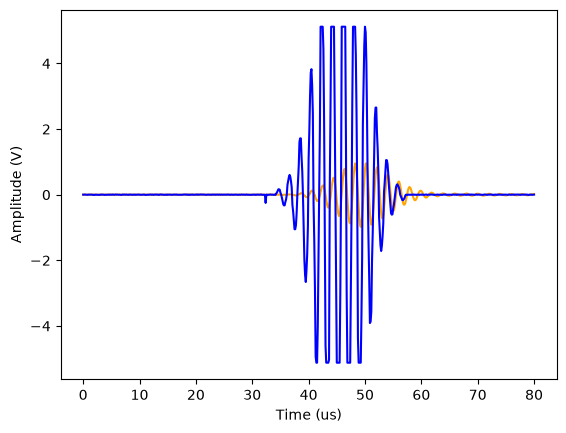

In [ ]:
import pandas as pd

import matplotlib.pyplot as plt

from scipy.signal import wiener



data = pd.read_csv("2.csv")

data = data.iloc[len(data) // 2:].reset_index(drop=True)

data = data.set_index("time_s")

data = data.loc[0.001120:0.0012].copy()



gain_db = 6

reference_gain = 10 ** (gain_db / 20)

wiener_window = 5



measured_raw = data["measured_v"].to_numpy()

measured_filtered = wiener(measured_raw, mysize=wiener_window)

time_us = (data.index - data.index.min()) * 1e6



plt.figure(figsize=(10, 5))

plt.plot(

    time_us,

    measured_raw,

    color="orange",

    alpha=0.35,

    label="Received wave (raw)",

)

plt.plot(

    time_us,

    measured_filtered,

    color="darkorange",

    linewidth=1.5,

    label=f"Received wave (Wiener, window={wiener_window})",

)

plt.plot(

    time_us,

    data["reference_v"] * reference_gain,

    color="blue",

    label="Reference wave",

)



plt.xlabel("Time (us)")

plt.ylabel("Amplitude (V)")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


In [67]:
import sympy as sp



l = sp.Symbol("L")

dt = sp.Symbol(r"\Delta t")

t_del = sp.Symbol("t_d")



c = l / (dt - t_del)



vars = c.free_symbols

for var in vars:

    dx = sp.diff(c, var)

    print("Var:", var)

    print(sp.latex(dx))


Var: L
\frac{1}{\Delta t - t_{d}}
Var: \Delta t
- \frac{L}{\left(\Delta t - t_{d}\right)^{2}}
Var: t_d
\frac{L}{\left(\Delta t - t_{d}\right)^{2}}
